In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from glob import glob
from tqdm import tqdm
import plotly.express as px
from skmob.core.trajectorydataframe import TrajDataFrame
from skmob.preprocessing import detection
from skmob.measures import individual

In [2]:
file_path = "/glade/derecho/scratch/dgagne/veraset_cat/"


In [3]:
data_files = sorted(glob(file_path + "2024/03/27/" + "*.parquet"))

In [4]:
data_list = []
for data_file in tqdm(data_files):
    data_list.append(pd.read_parquet(data_file)[['utc_timestamp', 'caid', 'id_type', 'latitude', 'longitude']])
data = pd.concat(data_list)

100%|██████████| 1024/1024 [12:31<00:00,  1.36it/s]


In [5]:
data.reset_index(inplace=True)

In [6]:
tdf = TrajDataFrame(data, 
                    latitude="latitude", 
                    longitude="longitude",
                    datetime="utc_timestamp",
                    user_id="caid")

In [7]:
tdf_sorted = tdf.sort_values(by=["uid", "datetime"])

In [8]:
tdf_sorted

,index,datetime,uid,id_type,lat,lng
61900299,26945,2024-03-27 20:22:13,000002fdd77e569cebd49dccde91a9a4e4b7aaec563d51...,aaid,36.91891,-121.78992
61961923,88569,2024-03-27 20:22:14,000002fdd77e569cebd49dccde91a9a4e4b7aaec563d51...,aaid,36.91897,-121.78992
61936226,62872,2024-03-27 20:22:20,000002fdd77e569cebd49dccde91a9a4e4b7aaec563d51...,aaid,36.91896,-121.78991
61883253,9899,2024-03-27 20:22:24,000002fdd77e569cebd49dccde91a9a4e4b7aaec563d51...,aaid,36.91892,-121.78991
61894541,21187,2024-03-27 20:22:27,000002fdd77e569cebd49dccde91a9a4e4b7aaec563d51...,aaid,36.91890,-121.78991
...,...,...,...,...,...,...
19373755,29389,2024-03-27 06:43:44,fffffe6bc17118860ef11d5bf59a725c69b640a91dd276...,aaid,33.63586,-117.59534
19404830,60464,2024-03-27 06:43:45,fffffe6bc17118860ef11d5bf59a725c69b640a91dd276...,aaid,33.63584,-117.59537
19346905,2539,2024-03-27 06:43:46,fffffe6bc17118860ef11d5bf59a725c69b640a91dd276...,aaid,33.63580,-117.59535
3641873,96856,2024-03-27 05:51:41,ffffff9426eb4249b2a00d5b27174f0bd46f969f2f4fa7...,aaid,33.90763,-118.11972


In [9]:
users = pd.unique(tdf_sorted["uid"])

In [10]:
rand_users = np.random.choice(users, size=5000)

In [11]:
tdf_random = tdf_sorted[tdf_sorted["uid"].isin(rand_users)]

In [12]:
user_counts = tdf_sorted.groupby("uid")["uid"].count()

In [13]:
user_counts[user_counts > 3000]

uid
0209e932b31480786f2ffdb320dd24240d1f26712bf51badcfb6c887a574027d    3342
0245938770296fdc9f81bfe9c4617379ce58687c8a5a79cececa7362b5f3818e    3301
040ccaf3da3764d3ea7e7f98f313d44a408de5eed06268f92e405bc18fa13d51    4344
0d6379cc61f9ea8bf44c82317da9e9e2f7e88d4b9020efb8b6675fe153a46790    4034
0f117b704213fb2f88a44711f5fe73e9c103388fcf3534868ad6b3841a8e1302    3306
                                                                    ... 
eae02d47980798a54a0dde2be1c567f7baf841770199f2dfd833ac8dccb06b07    3776
ee9dc840f3cd8ff46ca65515b59dc51e493e6756c80e9129c6589790e8b0248d    3015
f4c06d397767b388ea014b65ac44fce619fca9eab3e86eba5ea2f365c6de6e8d    4279
f929495019beddc69957c9746305018df3466e81a9ce07d524745b12c7b47a83    3702
fd9fff16de5633ccf3eee496bc1c55c68aec6532ae8f56908409a56573be7c51    3527
Name: uid, Length: 116, dtype: int64

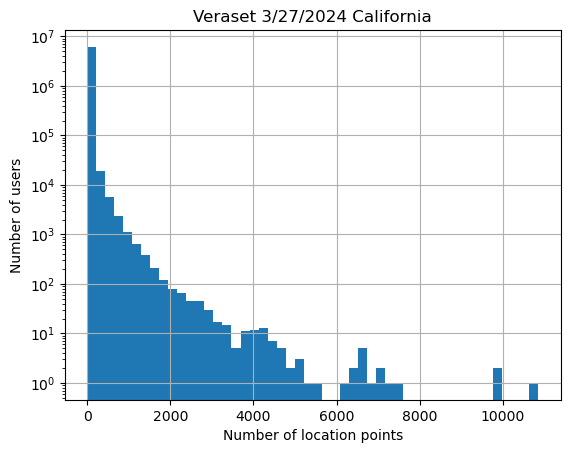

In [14]:
user_counts.hist(bins=50)
plt.gca().set_yscale("log")
plt.xlabel("Number of location points")
plt.ylabel("Number of users")
plt.title("Veraset 3/27/2024 California")
plt.savefig("veraset_user_counts.png", dpi=300, bbox_inches="tight")

In [15]:
tdf_u = tdf_sorted[tdf_sorted["uid"] == '21a4d54739489549988ed1af8519e840a73ec64e5430b331bb81f7fb149b552d']


In [16]:
tdf_u.shape

(1290, 6)

In [17]:
nlocs = individual.number_of_locations(tdf_random)

100%|██████████| 4998/4998 [00:04<00:00, 1097.96it/s]


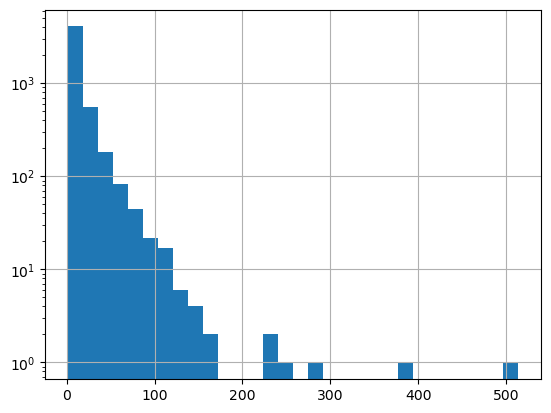

In [18]:
nlocs["number_of_locations"].hist(bins=30)
plt.gca().set_yscale("log")

In [19]:
nlocs["number_of_locations"].argmax()

2308

In [20]:
nlocs.iloc[621]["uid"]

'21131b17dcbf092a6a875cb45b454f1a95c0453d1c950d1a0a13305ac95a7561'

In [21]:
stays = detection.stay_locations(tdf_u, )

In [22]:
stays

,index,datetime,uid,id_type,lat,lng,leaving_datetime
0,30506,2024-03-27 03:17:26,21a4d54739489549988ed1af8519e840a73ec64e5430b3...,idfa,33.870360,-117.836597,2024-03-27 10:38:46
1,4876,2024-03-27 13:39:49,21a4d54739489549988ed1af8519e840a73ec64e5430b3...,idfa,35.010378,-118.263078,2024-03-27 14:15:15
2,20193,2024-03-27 14:15:15,21a4d54739489549988ed1af8519e840a73ec64e5430b3...,idfa,35.009708,-118.263634,2024-03-27 15:35:39
3,57188,2024-03-27 18:10:49,21a4d54739489549988ed1af8519e840a73ec64e5430b3...,idfa,33.958506,-118.108783,2024-03-27 19:13:14
4,40647,2024-03-27 20:00:34,21a4d54739489549988ed1af8519e840a73ec64e5430b3...,idfa,33.870363,-117.836557,2024-03-27 21:43:09
5,48638,2024-03-27 22:06:41,21a4d54739489549988ed1af8519e840a73ec64e5430b3...,idfa,33.818564,-117.836173,2024-03-27 22:38:42


In [23]:
map_f = tdf_u.plot_trajectory(max_points=None)
stays.plot_stops(map_f=map_f)

/glade/work/ggantos/conda-envs/cat/lib/python3.11/site-packages/skmob/core/trajectorydataframe.py:689: UserWarning: Only the trajectories of the first 10 users will be plotted. Use the argument `max_users` to specify the desired number of users, or filter the TrajDataFrame.
  return plot.plot_trajectory(
/glade/work/ggantos/conda-envs/cat/lib/python3.11/site-packages/skmob/core/trajectorydataframe.py:791: UserWarning: Only the stops of the first 10 users will be plotted. Use the argument `max_users` to specify the desired number of users, or filter the TrajDataFrame.
  return plot.plot_stops(


In [24]:
data["latitude"] = data["latitude"].astype(float)
data["longitude"] = data["longitude"].astype(float)

In [25]:
data["time"] = pd.to_datetime(data["utc_timestamp"])

In [26]:
pd.unique(data["caid"])[5]

'934858d4444e0fda7ea2cb3a8ac8501c3b6914bf0612e997fac1d56392492076'

In [27]:
one_person = data[data["caid"] == '118b21ada7f0eba15b85bac7e3832ff81f0d6a671943bb5a62d7ddedaf6544b4']

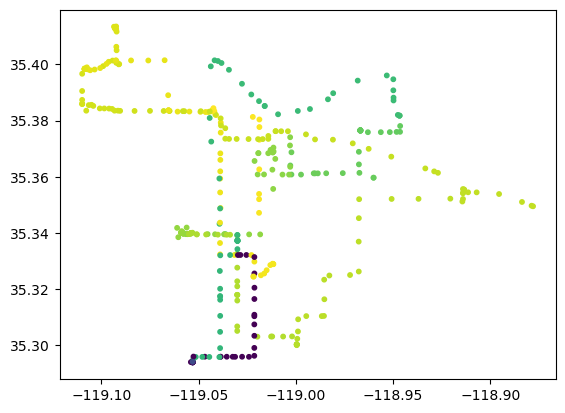

In [28]:
plt.scatter(one_person["longitude"].values, 
            one_person["latitude"].values, 10, one_person["time"])

In [29]:
fig = px.scatter_map(lat=one_person["latitude"], lon=one_person["longitude"],  map_style="open-street-map")
fig.show(renderer="iframe")